**import required libraries**

In [1]:
import numpy as np
import pandas as pd
import warnings
import json
import joblib

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import LinearSVC

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


**Configure project Paths**

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Processed Data:", DATA_PROCESSED_DIR)
print("Models:", MODELS_DIR)
print("Metrics:", RESULTS_METRICS_DIR)

Project Root: D:\AI-IDS
Processed Data: D:\AI-IDS\data\processed
Models: D:\AI-IDS\models
Metrics: D:\AI-IDS\results\metrics


**Load Processed Datasets**

In [3]:
train_path = DATA_PROCESSED_DIR / "train.csv"
validation_path = DATA_PROCESSED_DIR / "validation.csv"
test_path = DATA_PROCESSED_DIR / "test.csv"

required_files = [
    train_path,
    validation_path,
    test_path
]

for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f"Required file not found: {file}\n"
            "Run 01_data_preparation.ipynb first."
        )

train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)
test_df = pd.read_csv(test_path)

print("Datasets loaded successfully.\n")

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Datasets loaded successfully.

Training: (1764558, 75)
Validation: (378120, 75)
Test: (378120, 75)


**Prepare Features and Target**

In [4]:
feature_config_path = DATA_PROCESSED_DIR / "feature_config.json"

with open(feature_config_path, "r") as file:
    feature_config = json.load(file)

feature_columns = feature_config["features"]

print(f"Number of features: {len(feature_columns)}")

# Verify all features exist
for feature in feature_columns:
    if feature not in train_df.columns:
        raise KeyError(
            f"Feature '{feature}' is missing from training dataset."
        )

X_train = train_df[feature_columns].copy()
y_train = train_df["Attack"].copy()

X_val = validation_df[feature_columns].copy()
y_val = validation_df["Attack"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["Attack"].copy()

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)

Number of features: 74

Feature matrix shapes:
X_train: (1764558, 74)
X_val:   (378120, 74)
X_test:  (378120, 74)

Target shapes:
y_train: (1764558,)
y_val:   (378120,)
y_test:  (378120,)


**Dataset Verification**

In [5]:
def class_distribution(y):
    result = pd.DataFrame({
        "Count": y.value_counts(),
        "Percentage": y.value_counts(normalize=True) * 100
    })

    result.index = result.index.map({
        0: "BENIGN",
        1: "ATTACK"
    })

    return result


print("Training class distribution:")
display(class_distribution(y_train))

print("\nValidation class distribution:")
display(class_distribution(y_val))

print("\nTest class distribution:")
display(class_distribution(y_test))

print("\nMissing values:")
print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_val.isnull().sum().sum())
print("Test:", X_test.isnull().sum().sum())

print("\nInfinite values:")
print("Training:", np.isinf(X_train).sum().sum())
print("Validation:", np.isinf(X_val).sum().sum())
print("Test:", np.isinf(X_test).sum().sum())

Training class distribution:


,Count,Percentage
Attack,,
BENIGN,1466539,83.110841
ATTACK,298019,16.889159



Validation class distribution:


,Count,Percentage
Attack,,
BENIGN,314259,83.110917
ATTACK,63861,16.889083



Test class distribution:


,Count,Percentage
Attack,,
BENIGN,314259,83.110917
ATTACK,63861,16.889083



Missing values:
Training: 0
Validation: 0
Test: 0

Infinite values:
Training: 0
Validation: 0
Test: 0


**Build Preprocessing Pipelines**

In [6]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])


# Linear Support Vector Machine
linear_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        )
    )
])


# Random Forest
random_forest_pipeline = Pipeline([
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])


# Gradient Boosting
gradient_boosting_pipeline = Pipeline([
    (
        "model",
        GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
    )
])


print("All machine learning pipelines created successfully.")

All machine learning pipelines created successfully.


**Define ML Models**

In [7]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "LinearSVC": linear_svm_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

print("Models to be trained:")

for name in models:
    print(" -", name)

Models to be trained:
 - Logistic Regression
 - Random Forest
 - LinearSVC
 - Gradient Boosting


**1. Train Logistic Regression**

In [8]:
print("Training Logistic Regression...")

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Training Logistic Regression...
Logistic Regression training completed.


**2. Train Random Forest**

In [9]:
print("Training Random Forest...")

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Training Random Forest...
Random Forest training completed.


**3. Train LinearSVC**

In [10]:
print("Training LinearSVC...")

linear_svm_pipeline.fit(X_train,y_train)

print("LinearSVC training completed.")

Training LinearSVC...
LinearSVC training completed.


**4. Train Gradient Boosting**

In [11]:
print("Training Gradient Boosting...")

gradient_boosting_pipeline.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Training Gradient Boosting...
Gradient Boosting training completed.


**Validation Model Comparison**

In [13]:
trained_models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "LinearSVC": linear_svm_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

validation_results = []

for name, model in trained_models.items():

    print(f"Evaluating {name}...")

    y_pred = model.predict(X_val)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val,
            y_pred,
            zero_division=0
        )
    })

validation_results_df = pd.DataFrame(
    validation_results
)

validation_results_df = validation_results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(validation_results_df)

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating LinearSVC...
Evaluating Gradient Boosting...


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.998926,0.995440,0.998215,0.996826
1,Gradient Boosting,0.997281,0.995317,0.988553,0.991924
2,Logistic Regression,0.939123,0.743926,0.975243,0.844023
3,LinearSVC,0.935116,0.730930,0.974585,0.835353


**Save Baseline Model Comparison**

In [14]:
baseline_results_path = (
    RESULTS_METRICS_DIR / "baseline_model_comparison.csv"
)

validation_results_df.to_csv(
    baseline_results_path,
    index=False
)

print("Baseline comparison saved to:")
print(baseline_results_path)

Baseline comparison saved to:
D:\AI-IDS\results\metrics\baseline_model_comparison.csv


**Cross-Validation**

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = []

for name, model in trained_models.items():

    print(f"Cross-validating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Precision Mean": scores["test_precision"].mean(),
        "CV Recall Mean": scores["test_recall"].mean(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="CV F1 Mean",
    ascending=False
).reset_index(drop=True)

display(cv_results_df)

Cross-validating Logistic Regression...
Cross-validating Random Forest...
Cross-validating LinearSVC...
Cross-validating Gradient Boosting...


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV F1 Std
0,Random Forest,0.998850,0.995387,0.997816,0.996600,0.000127
1,Gradient Boosting,0.997301,0.996009,0.987977,0.991976,0.000630
2,Logistic Regression,0.939092,0.743887,0.975075,0.843934,0.000650
3,LinearSVC,0.935379,0.731629,0.975045,0.835978,0.000724


**Model Performance Visualization**

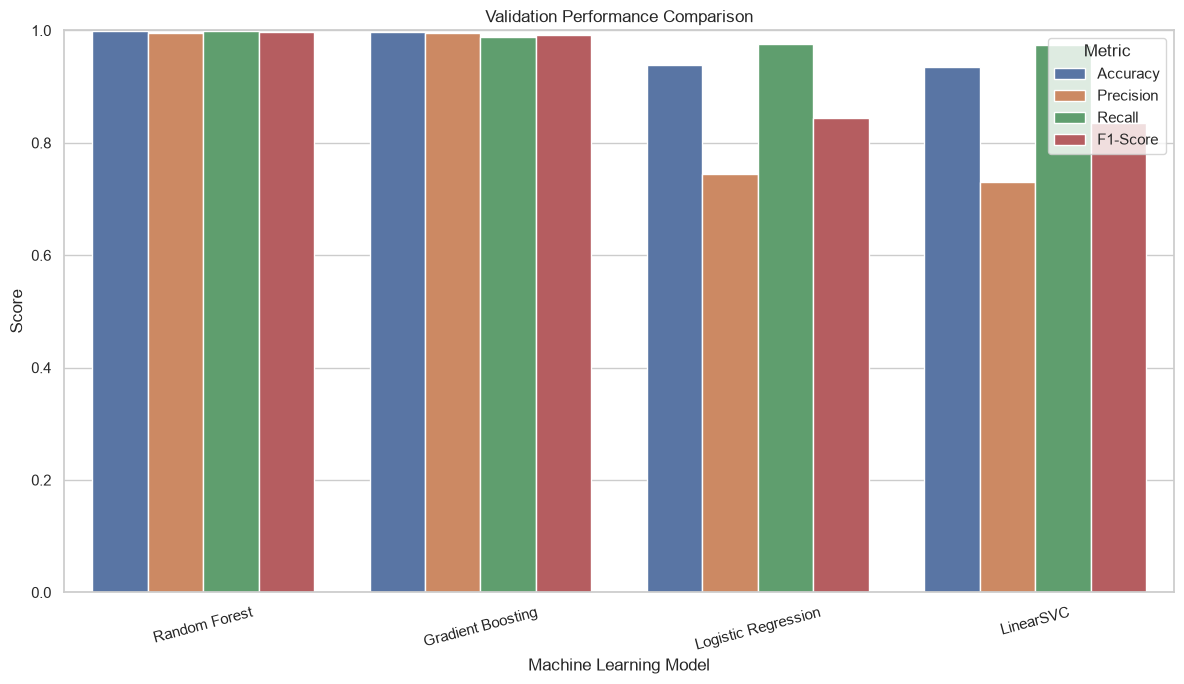

Performance comparison saved to:
D:\AI-IDS\results\figures\model_performance_comparison.png


In [22]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

# Convert results into plotting format
plot_data = validation_results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Validation Performance Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=15
)

plt.legend(
    title="Metric"
)

plt.tight_layout()

figure_path = (
    RESULTS_FIGURES_DIR /
    "model_performance_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance comparison saved to:")
print(figure_path)

**Cross-Validation Performance Visualization**

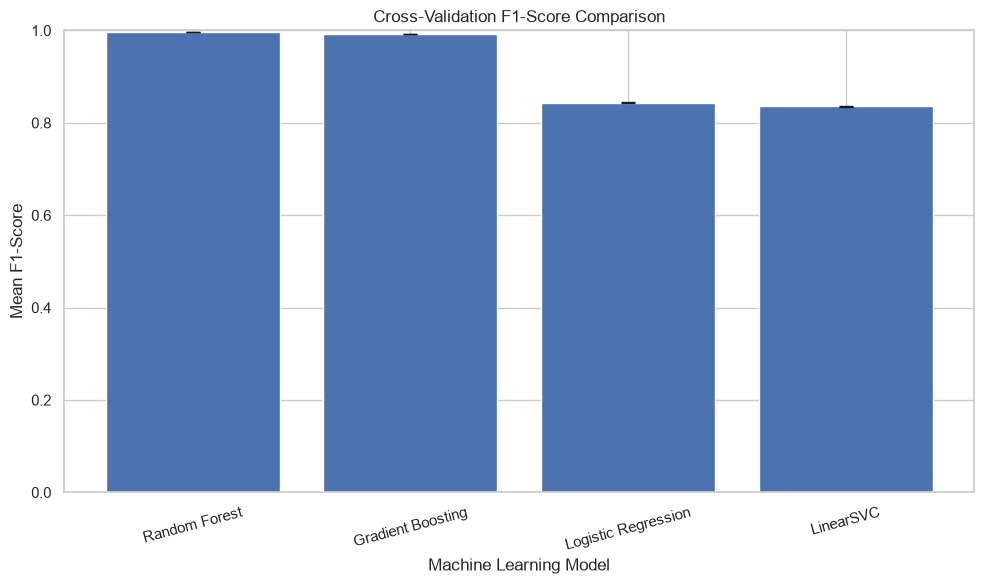

Cross-validation figure saved to:
D:\AI-IDS\results\figures\cross_validation_f1_comparison.png


In [23]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["CV F1 Mean"],
    yerr=cv_results_df["CV F1 Std"],
    capsize=5
)

plt.title(
    "Cross-Validation F1-Score Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Mean F1-Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=15
)

plt.tight_layout()

figure_path = (
    RESULTS_FIGURES_DIR /
    "cross_validation_f1_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Cross-validation figure saved to:")
print(figure_path)

**Feature Importance Analysis**

In [24]:
# Access the Random Forest model from the pipeline
rf_model = random_forest_pipeline.named_steps["model"]

# Extract feature importance
feature_importance = pd.DataFrame({

    "Feature": feature_columns,

    "Importance":
        rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False

).reset_index(
    drop=True
)

print("Top 20 Important Features:")

display(
    feature_importance.head(20)
)

Top 20 Important Features:


,Feature,Importance
0,Packet_Length_Std,0.066096
1,Bwd_Packet_Length_Std,0.061629
2,Average_Packet_Size,0.059150
3,Packet_Length_Variance,0.052252
4,Destination_Port,0.048243
5,Bwd_Packet_Length_Mean,0.043105
6,Max_Packet_Length,0.038455
7,Avg_Bwd_Packet_Size,0.038115
8,Packet_Length_Mean,0.037839
9,Fwd_Packet_Length_Max,0.036369


**Feature Importance Visualization**

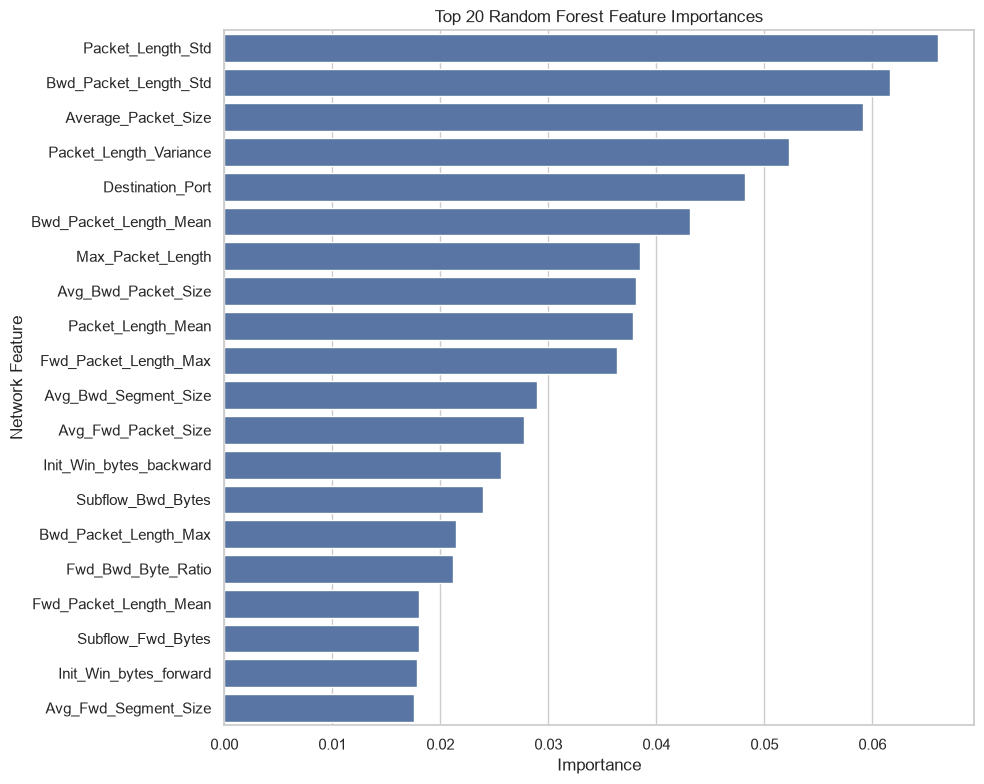

Feature importance figure saved to:
D:\AI-IDS\results\figures\feature_importance.png


In [25]:
top_features = feature_importance.head(20)

plt.figure(
    figsize=(10, 8)
)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Random Forest Feature Importances"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Network Feature"
)

plt.tight_layout()

figure_path = (
    RESULTS_FIGURES_DIR /
    "feature_importance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance figure saved to:")
print(figure_path)

**Save Feature Importance**

In [26]:
feature_importance_path = (
    RESULTS_METRICS_DIR /
    "feature_importance.csv"
)

feature_importance.to_csv(
    feature_importance_path,
    index=False
)

print("Feature importance saved to:")
print(feature_importance_path)

Feature importance saved to:
D:\AI-IDS\results\metrics\feature_importance.csv


**Select Final Model**

In [27]:
best_model_name = validation_results_df.iloc[0]["Model"]

print("Selected Final Model:")
print(
    best_model_name
)

print("\nValidation Performance:")

display(
    validation_results_df.iloc[[0]]
)

Selected Final Model:
Random Forest

Validation Performance:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.998926,0.99544,0.998215,0.996826


**Verify Selected Model Using Cross-Validation**

In [28]:
selected_cv_result = cv_results_df[
    cv_results_df["Model"] == best_model_name
]

print("Selected Model Cross-Validation Result:")

display(
    selected_cv_result
)

Selected Model Cross-Validation Result:


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV F1 Std
0,Random Forest,0.99885,0.995387,0.997816,0.9966,0.000127


**Prepare Final Training Dataset**

In [29]:
X_train_final = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0,
    ignore_index=True
)

y_train_final = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0,
    ignore_index=True
)


print("Final training dataset:")
print(
    "Samples:",
    f"{len(X_train_final):,}"
)

print(
    "Features:",
    X_train_final.shape[1]
)

print(
    "\nFinal target dataset:",
    len(y_train_final)
)

Final training dataset:
Samples: 2,142,678
Features: 74

Final target dataset: 2142678


**Final Training Class Distribution**

In [30]:
print(
    "Final Training Class Distribution:"
)

display(
    class_distribution(
        y_train_final
    )
)

Final Training Class Distribution:


,Count,Percentage
Attack,,
BENIGN,1780798,83.110855
ATTACK,361880,16.889145


**Train Final Model**

In [31]:
print(
    f"Training final model: {best_model_name}"
)

print(
    f"Training samples: {len(X_train_final):,}"
)

print(
    f"Features: {X_train_final.shape[1]}"
)

print("\nTraining...")


# Select the corresponding model pipeline
if best_model_name == "Logistic Regression":

    final_model = Pipeline([
        ("scaler", StandardScaler()),

        (
            "model",
            LogisticRegression(
                C=1.0,
                class_weight="balanced",
                solver="liblinear",
                max_iter=500,
                random_state=42
            )
        )
    ])


elif best_model_name == "Random Forest":

    final_model = Pipeline([
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ])


elif best_model_name == "LinearSVC":

    final_model = Pipeline([
        ("scaler", StandardScaler()),

        (
            "model",
            LinearSVC(
                C=1.0,
                class_weight="balanced",
                max_iter=5000,
                random_state=42
            )
        )
    ])


elif best_model_name == "Gradient Boosting":

    final_model = Pipeline([
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=3,
                random_state=42
            )
        )
    ])


else:

    raise ValueError(
        f"Unknown model selected: {best_model_name}"
    )


# Train final model
final_model.fit(
    X_train_final,
    y_train_final
)


print("\nFinal model training completed successfully.")

Training final model: Random Forest
Training samples: 2,142,678
Features: 74

Training...

Final model training completed successfully.


**Save Final Model**

In [32]:
final_model_path = (
    MODELS_DIR /
    "final_ids_model.pkl"
)

joblib.dump(
    final_model,
    final_model_path
)

print(
    "Final model saved successfully:"
)

print(
    final_model_path
)

Final model saved successfully:
D:\AI-IDS\models\final_ids_model.pkl


**Save Model Metadata**

In [33]:
model_metadata = {

    "project":
        "AI-Based Intrusion Detection System",

    "dataset":
        "CICIDS2017",

    "task":
        "Binary Intrusion Detection",

    "target":
        "Attack",

    "target_mapping": {
        "0": "BENIGN",
        "1": "ATTACK"
    },

    "selected_model":
        best_model_name,

    "selection_metric":
        "Validation F1-Score",

    "number_of_features":
        len(feature_columns),

    "features":
        feature_columns,

    "training_samples":
        int(len(X_train_final)),

    "random_state":
        42
}


metadata_path = (
    MODELS_DIR /
    "model_metadata.json"
)


with open(
    metadata_path,
    "w"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4
    )


print(
    "Model metadata saved to:"
)

print(
    metadata_path
)

Model metadata saved to:
D:\AI-IDS\models\model_metadata.json


**Save Model Development Results**

In [34]:
validation_results_path = (
    RESULTS_METRICS_DIR /
    "validation_model_comparison.csv"
)

cv_results_path = (
    RESULTS_METRICS_DIR /
    "cross_validation_results.csv"
)

feature_importance_path = (
    RESULTS_METRICS_DIR /
    "feature_importance.csv"
)


# Save validation results
validation_results_df.to_csv(
    validation_results_path,
    index=False
)


# Save cross-validation results
cv_results_df.to_csv(
    cv_results_path,
    index=False
)


# Save feature importance
feature_importance.to_csv(
    feature_importance_path,
    index=False
)


print("Model development results saved:")
print()
print(validation_results_path)
print(cv_results_path)
print(feature_importance_path)

Model development results saved:

D:\AI-IDS\results\metrics\validation_model_comparison.csv
D:\AI-IDS\results\metrics\cross_validation_results.csv
D:\AI-IDS\results\metrics\feature_importance.csv


**Final Model Verification**

In [35]:
# ============================================================
# CELL 30: FINAL MODEL VERIFICATION
# ============================================================

print("FINAL MODEL VERIFICATION")
print("=" * 55)


# ------------------------------------------------------------
# Check files
# ------------------------------------------------------------

print(
    "Model file exists:",
    final_model_path.exists()
)

print(
    "Metadata file exists:",
    metadata_path.exists()
)


# ------------------------------------------------------------
# Model information
# ------------------------------------------------------------

print(
    "\nSelected model:",
    best_model_name
)

print(
    "Number of features:",
    len(feature_columns)
)

print(
    "Final training samples:",
    f"{len(X_train_final):,}"
)

print(
    "Test samples:",
    f"{len(X_test):,}"
)


# ------------------------------------------------------------
# Load saved model
# ------------------------------------------------------------

loaded_model = joblib.load(
    final_model_path
)

print(
    "\nSaved model loaded successfully."
)


# ------------------------------------------------------------
# Generate sample predictions
# ------------------------------------------------------------

sample_size = min(
    10,
    len(X_test)
)

sample_predictions = loaded_model.predict(
    X_test.iloc[:sample_size]
)


print(
    "\nSample predictions:"
)

print(
    sample_predictions
)


# ------------------------------------------------------------
# Prediction labels
# ------------------------------------------------------------

prediction_labels = np.where(
    sample_predictions == 0,
    "BENIGN",
    "ATTACK"
)


print(
    "\nPrediction labels:"
)

print(
    prediction_labels
)


print(
    "\nFinal model verification completed successfully."
)

FINAL MODEL VERIFICATION
Model file exists: True
Metadata file exists: True

Selected model: Random Forest
Number of features: 74
Final training samples: 2,142,678
Test samples: 378,120

Saved model loaded successfully.

Sample predictions:
[0 0 0 0 0 0 0 0 0 0]

Prediction labels:
['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN']

Final model verification completed successfully.
